In [1]:
import csv
import heapq
import os
from collections import deque

import matplotlib.pyplot as plt

print(sorted(os.listdir('datos')))

['heuristica_lima.csv', 'heuristica_trujillo.csv', 'rutas_peru_norte.csv', 'rutas_peru_sur.csv']


In [2]:
def leer_aristas(ruta):
    """Devuelve las filas del CSV tal como vienen, sin limpiar (lista de dicts)."""
    with open(ruta, encoding="utf-8", newline="") as f:
        return list(csv.DictReader(f))


def leer_heuristica(ruta):
    """Devuelve {ciudad: h_km}. Se aplica strip() al nombre por seguridad."""
    with open(ruta, encoding="utf-8", newline="") as f:
        return {fila["ciudad"].strip(): int(fila["h_km"])
                for fila in csv.DictReader(f)}


filas = leer_aristas('datos/rutas_peru_sur.csv')
H = leer_heuristica('datos/heuristica_lima.csv')

print('Filas leidas:', len(filas))
for f in filas:
    print(repr(f['origen']), '|', repr(f['destino']), '|',
          repr(f['distancia_km']))

print('Ciudades en la heuristica:', len(H))

Filas leidas: 16
'Cusco' | 'Abancay' | '195'
'Abancay' | 'Andahuaylas' | '138'
'Abancay' | 'Puquio' | '350'
'Andahuaylas' | 'Ayacucho' | '260'
'Ayacucho' | 'Huancavelica' | '245'
'Ayacucho' | 'Pisco' | '320'
'Huancavelica' | 'Huancayo' | '147'
'Huancayo' | 'La Oroya' | '125'
'La Oroya' | 'Lima' | '187'
'Puquio' | 'Nazca' | '155'
'Nasca ' | 'Ica' | '145'
'Ica' | 'Pisco' | '75'
'Pisco' | 'Chincha' | '60'
'Chincha' | 'Lima' | '200'
'Chincha' | 'Lima' | '200'
' Lima' | 'La Oroya' | ''
Ciudades en la heuristica: 13


In [3]:
ALIAS = {"nazca": "Nasca"}      # variantes de nombre -> nombre normalizado


def normalizar(nombre):
    nombre = nombre.strip()                     # R1: espacios sobrantes
    return ALIAS.get(nombre.lower(), nombre)    # R2: variantes de nombre


def limpiar(filas):
    """TODO 2.1 - Aplica R1..R4 y devuelve [(origen, destino, distancia_km)]."""
    aristas = []
    vistas = set()
    for fila in filas:
        origen = normalizar(fila["origen"])
        destino = normalizar(fila["destino"])
        try:                                    # R3: distancia valida
            distancia = int(fila["distancia_km"])
        except (TypeError, ValueError):
            continue
        clave = frozenset({origen, destino})    # R4: A-B y B-A son la misma
        if clave in vistas:
            continue
        vistas.add(clave)
        aristas.append((origen, destino, distancia))
    return aristas


def construir_grafo(aristas):
    """TODO 2.2 - Lista de adyacencia no dirigida, vecinos en orden alfabetico."""
    G = {}
    for a, b, d in aristas:
        G.setdefault(a, []).append((b, d))
        G.setdefault(b, []).append((a, d))
    for ciudad in G:
        G[ciudad].sort()
    return G


aristas = limpiar(filas)
G = construir_grafo(aristas)

print('Aristas limpias:', len(aristas))
print('Ciudades:', len(G))
print('Vecinos de Abancay:', G['Abancay'])
print('Vecinos de Pisco :', G['Pisco'])

# comprobacion de simetria del grafo no dirigido
for a in G:
    for b, costo in G[a]:
        assert (a, costo) in G[b], f'arista asimetrica: {a}-{b}'
print('Grafo simetrico: OK')

Aristas limpias: 14
Ciudades: 13
Vecinos de Abancay: [('Andahuaylas', 138), ('Cusco', 195), ('Puquio', 350)]
Vecinos de Pisco : [('Ayacucho', 320), ('Chincha', 60), ('Ica', 75)]
Grafo simetrico: OK


In [4]:
def costos_optimos_a(G, meta):
    """h*(n) para todo n, mediante Dijkstra hacia atras desde la meta."""
    dist = {meta: 0}
    pq = [(0, meta)]
    while pq:
        d, n = heapq.heappop(pq)
        if d > dist[n]:
            continue
        for m, costo in G[n]:
            if d + costo < dist.get(m, float("inf")):
                dist[m] = d + costo
                heapq.heappush(pq, (d + costo, m))
    return dist


def verificar_heuristica(G, h, meta):
    """TODO 3.1 - Devuelve (ciudades no admisibles, pares (n, m) inconsistentes)."""
    h_estrella = costos_optimos_a(G, meta)
    no_admisibles = [n for n in G if h[n] > h_estrella[n]]
    inconsistentes = [(n, m) for n in G for m, c in G[n]
                      if h[n] > c + h[m]]
    return no_admisibles, inconsistentes


no_adm, inc = verificar_heuristica(G, H, 'Lima')
print('Admisible :', 'SI' if not no_adm else no_adm)
print('Consistente:', 'SI' if not inc else inc)

h_estrella = costos_optimos_a(G, 'Lima')
print(f"{'ciudad':14s}{'h':>6s}{'h*':>7s}{'h/h*':>8s}")
razones = []
for ciudad in sorted(H, key=lambda x: h_estrella[x]):
    razon = H[ciudad] / h_estrella[ciudad] if h_estrella[ciudad] else 1.0
    if h_estrella[ciudad]:
        razones.append(razon)
    print(f'{ciudad:14s}{H[ciudad]:6d}{h_estrella[ciudad]:7d}{razon:8.2f}')
print(f'Razon h/h* promedio (sin contar Lima): {sum(razones) / len(razones):.2f}')

Admisible : SI
Consistente: SI
ciudad             h     h*    h/h*
Lima               0      0    1.00
La Oroya         110    187    0.59
Chincha          165    200    0.82
Pisco            190    260    0.73
Huancayo         170    312    0.54
Ica              240    335    0.72
Huancavelica     210    459    0.46
Nasca            320    480    0.67
Ayacucho         265    580    0.46
Puquio           380    635    0.60
Andahuaylas      390    840    0.46
Abancay          425    978    0.43
Cusco            574   1173    0.49
Razon h/h* promedio (sin contar Lima): 0.58


In [5]:
class Metricas:
    """expandidos  : nodos extraidos y procesados (sin obsoletos, meta incluida).
    generados   : inserciones en la frontera (incluye el nodo inicial).
    frontera_max: mayor tamano de la frontera, medido antes de cada extraccion."""

    def __init__(self, nombre):
        self.nombre = nombre
        self.expandidos = 0
        self.generados = 0
        self.frontera_max = 0

    def observar_frontera(self, tamano):
        self.frontera_max = max(self.frontera_max, tamano)

    def expandir(self):
        self.expandidos += 1

    def generar(self):
        self.generados += 1

    def fila(self, costo):
        return (self.nombre, costo, self.expandidos, self.generados,
                self.frontera_max)


def reconstruir(padre, meta):
    camino, actual = [], meta
    while actual is not None:
        camino.append(actual)
        actual = padre[actual]
    return camino[::-1]


def costo_camino(G, camino):
    return sum(dict(G[a])[b] for a, b in zip(camino, camino[1:]))

In [6]:
def bfs(G, inicio, meta):
    """TODO 5.1 - Cola FIFO; se marca visitado al GENERAR."""
    m = Metricas("BFS")
    padre = {inicio: None}
    frontera = deque([inicio])
    m.generar()
    visitados = {inicio}
    while frontera:
        m.observar_frontera(len(frontera))
        n = frontera.popleft()
        m.expandir()
        if n == meta:
            camino = reconstruir(padre, meta)
            return camino, costo_camino(G, camino), m
        for vecino, _costo in G[n]:
            if vecino not in visitados:
                visitados.add(vecino)
                padre[vecino] = n
                frontera.append(vecino)
                m.generar()
    return None, None, m


def dfs(G, inicio, meta):
    """TODO 5.2 - Pila explicita; vecinos apilados en orden alfabetico inverso.
    Se marca como cerrado al EXPANDIR: una ciudad puede quedar apilada mas de
    una vez y las copias repetidas se descartan al desapilarlas."""
    m = Metricas("DFS")
    padre = {}
    frontera = [(inicio, None)]         # (ciudad, desde donde se apilo)
    m.generar()
    cerrados = set()
    while frontera:
        m.observar_frontera(len(frontera))
        n, p = frontera.pop()
        if n in cerrados:               # entrada obsoleta: no cuenta
            continue
        padre[n] = p
        m.expandir()
        if n == meta:
            camino = reconstruir(padre, meta)
            return camino, costo_camino(G, camino), m
        cerrados.add(n)
        for vecino, _costo in reversed(G[n]):
            if vecino not in cerrados:
                frontera.append((vecino, n))
                m.generar()
    return None, None, m


for camino, costo, m in [bfs(G, 'Cusco', 'Lima'), dfs(G, 'Cusco', 'Lima')]:
    print(f'{m.nombre}: {costo} km | expandidos={m.expandidos} '
          f'generados={m.generados} frontera_max={m.frontera_max}')
    print('   ', ' -> '.join(camino))

BFS: 1173 km | expandidos=13 generados=13 frontera_max=3
    Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Pisco -> Chincha -> Lima
DFS: 1297 km | expandidos=8 generados=10 frontera_max=3
    Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Huancavelica -> Huancayo -> La Oroya -> Lima


In [7]:
def costo_uniforme(G, inicio, meta):
    h_nula = {ciudad: 0 for ciudad in G}    # se construye con el grafo recibido
    camino, costo, m = a_estrella(G, inicio, meta, h_nula)
    m.nombre = "Costo uniforme"
    return camino, costo, m

In [8]:
def greedy_best_first(G, inicio, meta, h):
    """TODO 7.1"""
    m = Metricas("Greedy")
    padre = {inicio: None}
    frontera = [(h[inicio], 0, inicio)]     # (prioridad, desempate, ciudad)
    m.generar()
    en_frontera = {inicio}
    cerrados = set()
    orden = 0
    while frontera:
        m.observar_frontera(len(frontera))
        _, _, n = heapq.heappop(frontera)
        en_frontera.discard(n)
        m.expandir()
        if n == meta:
            camino = reconstruir(padre, meta)
            return camino, costo_camino(G, camino), m
        cerrados.add(n)
        for vecino, _costo in G[n]:
            if vecino in cerrados or vecino in en_frontera:
                continue
            padre[vecino] = n
            orden += 1
            en_frontera.add(vecino)
            m.generar()
            heapq.heappush(frontera, (h[vecino], orden, vecino))
    return None, None, m


camino, costo, m = greedy_best_first(G, 'Cusco', 'Lima', H)
print(f'{m.nombre}: {costo} km | expandidos={m.expandidos} '
      f'generados={m.generados} frontera_max={m.frontera_max}')
print('   ', ' -> '.join(camino))

Greedy: 1180 km | expandidos=8 generados=10 frontera_max=3
    Cusco -> Abancay -> Puquio -> Nasca -> Ica -> Pisco -> Chincha -> Lima


In [9]:
def a_estrella(G, inicio, meta, h, w=1.0, traza=False):
    """TODO 8.1 - Con w = 1 es A* clasico."""
    m = Metricas("A*")
    g = {inicio: 0}
    padre = {inicio: None}
    frontera = [(w * h[inicio], 0, inicio)]
    m.generar()
    cerrados = set()
    orden = 0
    while frontera:
        m.observar_frontera(len(frontera))
        f, _, n = heapq.heappop(frontera)
        if n in cerrados:               # entrada obsoleta: no cuenta
            continue
        m.expandir()
        if traza:
            print(f"  paso {m.expandidos:2d}: expande {n:13s} g={g[n]:5d} "
                  f"h={h[n]:4d} f={f:7.1f}")
        if n == meta:                   # prueba de meta al EXTRAER
            return reconstruir(padre, meta), g[meta], m
        cerrados.add(n)
        for vecino, costo in G[n]:
            g_tentativo = g[n] + costo
            if g_tentativo < g.get(vecino, float("inf")):   # solo si mejora
                g[vecino] = g_tentativo
                padre[vecino] = n
                cerrados.discard(vecino)    # solo actua si h no es consistente
                orden += 1
                m.generar()
                heapq.heappush(frontera,
                               (g_tentativo + w * h[vecino], orden, vecino))
    return None, None, m


camino, costo, m = a_estrella(G, 'Cusco', 'Lima', H, traza=True)
print(' -> '.join(camino))
print(f'costo={costo} expandidos={m.expandidos} '
      f'generados={m.generados} frontera_max={m.frontera_max}')

camino, costo, m = costo_uniforme(G, 'Cusco', 'Lima')
print(f'\nCosto uniforme: costo={costo} expandidos={m.expandidos}')

  paso  1: expande Cusco         g=    0 h= 574 f=  574.0
  paso  2: expande Abancay       g=  195 h= 425 f=  620.0
  paso  3: expande Andahuaylas   g=  333 h= 390 f=  723.0
  paso  4: expande Ayacucho      g=  593 h= 265 f=  858.0
  paso  5: expande Puquio        g=  545 h= 380 f=  925.0
  paso  6: expande Nasca         g=  700 h= 320 f= 1020.0
  paso  7: expande Huancavelica  g=  838 h= 210 f= 1048.0
  paso  8: expande Ica           g=  845 h= 240 f= 1085.0
  paso  9: expande Pisco         g=  913 h= 190 f= 1103.0
  paso 10: expande Chincha       g=  973 h= 165 f= 1138.0
  paso 11: expande Huancayo      g=  985 h= 170 f= 1155.0
  paso 12: expande Lima          g= 1173 h=   0 f= 1173.0
Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Pisco -> Chincha -> Lima
costo=1173 expandidos=12 generados=13 frontera_max=3

Costo uniforme: costo=1173 expandidos=13


In [10]:
def imprimir_tabla(resultados):
    print(f"{'Algoritmo':<16}{'Costo (km)':>11}{'Expandidos':>12}"
          f"{'Generados':>11}{'Frontera max.':>15}")
    print("-" * 65)
    for nombre, costo, exp, gen, fmax in resultados:
        print(f"{nombre:<16}{costo:>11}{exp:>12}{gen:>11}{fmax:>15}")


INICIO, META = 'Cusco', 'Lima'
resultados = []
for camino, costo, m in [bfs(G, INICIO, META),
                         dfs(G, INICIO, META),
                         costo_uniforme(G, INICIO, META),
                         greedy_best_first(G, INICIO, META, H),
                         a_estrella(G, INICIO, META, H)]:
    resultados.append(m.fila(costo))
imprimir_tabla(resultados)

Algoritmo        Costo (km)  Expandidos  Generados  Frontera max.
-----------------------------------------------------------------
BFS                    1173          13         13              3
DFS                    1297           8         10              3
Costo uniforme         1173          13         13              3
Greedy                 1180           8         10              3
A*                     1173          12         13              3


w=1.0  costo= 1173 expandidos= 12 exceso=  0.0 % cota w*C*=1173
w=1.5  costo= 1173 expandidos= 11 exceso=  0.0 % cota w*C*=1760
w=2.0  costo= 1173 expandidos=  8 exceso=  0.0 % cota w*C*=2346
w=3.0  costo= 1173 expandidos=  8 exceso=  0.0 % cota w*C*=3519
w=5.0  costo= 1173 expandidos=  7 exceso=  0.0 % cota w*C*=5865


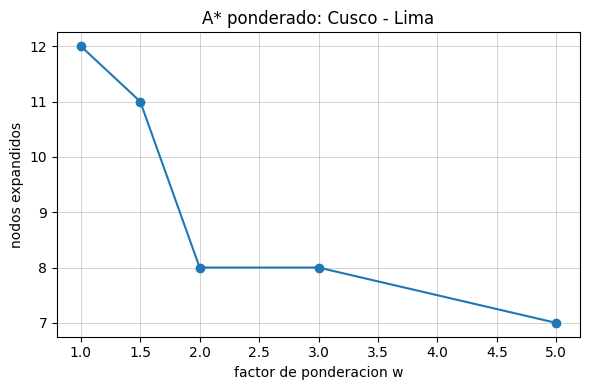

In [11]:
resultados_w = []
for w in (1.0, 1.5, 2.0, 3.0, 5.0):
    camino, costo, m = a_estrella(G, 'Cusco', 'Lima', H, w=w)
    exceso = 100 * (costo - 1173) / 1173
    resultados_w.append((w, costo, m.expandidos, exceso))
    print(f'w={w:<4} costo={costo:5d} expandidos={m.expandidos:3d} '
          f'exceso={exceso:5.1f} % cota w*C*={w*1173:.0f}')

ws = [r[0] for r in resultados_w]
expandidos = [r[2] for r in resultados_w]

os.makedirs('figuras', exist_ok=True)
plt.figure(figsize=(6, 4))
plt.plot(ws, expandidos, marker='o')
plt.xlabel('factor de ponderacion w')
plt.ylabel('nodos expandidos')
plt.title('A* ponderado: Cusco - Lima')
plt.grid(True, linewidth=0.4)
plt.tight_layout()
plt.savefig('figuras/ponderado.png', dpi=150)
plt.show()

In [12]:
H_mala = dict(H)
H_mala['Ayacucho'] = 700                  # el valor real de h* es 580

no_adm, inc = verificar_heuristica(G, H_mala, 'Lima')
print('No admisibles :', no_adm)
print('Inconsistentes:', inc)

camino, costo, m = a_estrella(G, 'Cusco', 'Lima', H_mala, traza=True)
print(' -> '.join(camino))
print('costo =', costo, '| expandidos =', m.expandidos)

No admisibles : ['Ayacucho']
Inconsistentes: [('Ayacucho', 'Andahuaylas'), ('Ayacucho', 'Huancavelica'), ('Ayacucho', 'Pisco')]
  paso  1: expande Cusco         g=    0 h= 574 f=  574.0
  paso  2: expande Abancay       g=  195 h= 425 f=  620.0
  paso  3: expande Andahuaylas   g=  333 h= 390 f=  723.0
  paso  4: expande Puquio        g=  545 h= 380 f=  925.0
  paso  5: expande Nasca         g=  700 h= 320 f= 1020.0
  paso  6: expande Ica           g=  845 h= 240 f= 1085.0
  paso  7: expande Pisco         g=  920 h= 190 f= 1110.0
  paso  8: expande Chincha       g=  980 h= 165 f= 1145.0
  paso  9: expande Lima          g= 1180 h=   0 f= 1180.0
Cusco -> Abancay -> Puquio -> Nasca -> Ica -> Pisco -> Chincha -> Lima
costo = 1180 | expandidos = 9


In [13]:
# T1. Grafo ampliado
filas_norte = leer_aristas('datos/rutas_peru_norte.csv')
aristas_norte = limpiar(filas_norte)
G2 = construir_grafo(aristas + aristas_norte)

print('Aristas:', len(aristas) + len(aristas_norte), '| Ciudades:', len(G2))

# T2. Heuristica hacia la nueva meta
HT = leer_heuristica('datos/heuristica_trujillo.csv')
no_adm, inc = verificar_heuristica(G2, HT, 'Trujillo')
print('Admisible :', 'SI' if not no_adm else no_adm)
print('Consistente:', 'SI' if not inc else inc)

# T3. Comparacion de los cinco algoritmos
INICIO, META = 'Cusco', 'Trujillo'
resultados = []
rutas = {}
for camino, costo, m in [bfs(G2, INICIO, META),
                         dfs(G2, INICIO, META),
                         costo_uniforme(G2, INICIO, META),
                         greedy_best_first(G2, INICIO, META, HT),
                         a_estrella(G2, INICIO, META, HT)]:
    resultados.append(m.fila(costo))
    rutas[m.nombre] = camino
print()
imprimir_tabla(resultados)

print('\nRutas encontradas:')
for nombre, camino in rutas.items():
    print(f'  {nombre:15s}', ' -> '.join(camino))

Aristas: 20 | Ciudades: 18
Admisible : SI
Consistente: SI

Algoritmo        Costo (km)  Expandidos  Generados  Frontera max.
-----------------------------------------------------------------
BFS                    1738          18         18              3
DFS                    1862          12         17              6
Costo uniforme         1738          18         18              3
Greedy                 1862          12         16              5
A*                     1738          17         19              3

Rutas encontradas:
  BFS             Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Pisco -> Chincha -> Lima -> Barranca -> Casma -> Chimbote -> Trujillo
  DFS             Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Huancavelica -> Huancayo -> La Oroya -> Lima -> Barranca -> Casma -> Chimbote -> Trujillo
  Costo uniforme  Cusco -> Abancay -> Andahuaylas -> Ayacucho -> Pisco -> Chincha -> Lima -> Barranca -> Casma -> Chimbote -> Trujillo
  Greedy          Cusco -> Abancay

In [14]:
C_OPT = 1738
for w in (1.0, 1.5, 2.0, 3.0):
    camino, costo, m = a_estrella(G2, INICIO, META, HT, w=w)
    exceso = 100 * (costo - C_OPT) / C_OPT
    print(f'w={w:<4} costo={costo:5d} expandidos={m.expandidos:3d} '
          f'exceso={exceso:5.1f} % cota w*C*={w*C_OPT:.0f} '
          f'cumple C <= w*C*: {"SI" if costo <= w * C_OPT else "NO"}')

w=1.0  costo= 1738 expandidos= 17 exceso=  0.0 % cota w*C*=1738 cumple C <= w*C*: SI
w=1.5  costo= 1738 expandidos= 15 exceso=  0.0 % cota w*C*=2607 cumple C <= w*C*: SI
w=2.0  costo= 1862 expandidos= 12 exceso=  7.1 % cota w*C*=3476 cumple C <= w*C*: SI
w=3.0  costo= 1862 expandidos= 12 exceso=  7.1 % cota w*C*=5214 cumple C <= w*C*: SI
